### Panorama-Kegeln – Lösung Schritt für Schritt

*33. Bundeswettbewerb Informatik (2014/2015), 2. Runde, Aufgabe 2*

Anna langweilt sich im Urlaub mit den Eltern. Da sie heute keine Kirche und kein Museum mehr sehen kann, bleibt sie lieber in der
Ferienwohnung und programmiert ein simuliertes Kegelspiel. Ihr Spiel soll aber etwas anders sein, und es soll nicht auf
Behändigkeit, sondern auf Überlegung und Planung ankommen.

Am Anfang einer Runde werden 20 Kegel auf einer Kreisscheibe mit Radius 2 platziert. Die Kegel sind punktförmig, und jeder wird,
unabhängig von den anderen, an einem Punkt platziert, der zufällig und gleichmäßig aus der gesamten Kreisscheibe gezogen wird. Dann
geht das eigentliche Spiel los, bei dem die Spieler abwechselnd eine Kugel mit Radius 1 werfen. Das Zentrum einer geworfenen Kugel
bewegt sich auf einer Geraden 𝓁, und die Kugel trifft jeden Kegel, dessen Abstand zu 𝓁 höchstens 1 beträgt.

Jeder von der Kugel eines Spielers getroffene Kegel wird aus dem Spiel entfernt und gibt dem Spieler einen Punkt.

Zu Hause will Anna gegen ihre Klassenkameraden spielen; aber im Urlaub ist sie allein, und so beschließt sie, gegen einen gedachten
Gegner Randy zu üben, der zufällig spielt. Genauer wählt Randy vor jedem seiner Kugelwürfe einen zufällig und gleichmäßig verteilten
Winkel v mit 0 ≤ v ≤ 360 und einen zufällig und gleichmäßig verteilten Punkt x in der Kreisscheibe und wirft seine Kugel dann aus der
Himmelsrichtung v so, dass ihr Zentrum x trifft.

Um kein zu leichtes Spiel gegen Randy zu haben, gibt ihm Anna einen buchstäblichen Startvorteil: Randy wirft immer die erste Kugel.
Danach spielen abwechselnd Anna und Randy. Nach jedem ihrer Würfe kann Anna wählen, die Runde zu beenden und eine neue anzufangen.
Ihr Ziel ist, über viele Spielrunden hinweg mehr Punkte als Randy zu sammeln.

#### Aufgabe

1. Überlege dir, wie man in einfacher und effizienter Weise die zufällige Platzierung der Kegel am Anfang einer Runde vornehmen kann.
   Implementiere dein Verfahren und eine graphische Ausgabe des Ergebnisses.
2. Implementiere den Rest des Spiels so, dass Anna am Rechner möglichst bequem gegen Randy im Rechner spielen kann.
3. Suche eine Strategie für Anna, mit der sie tatsächlich gegen Randy gewinnen kann. Implementiere deine Strategie so, dass man am
   Bildschirm verfolgen kann, wie Anna Randy nach und nach in die Knie zwingt.
4. Wie erfolgreich ist deine Strategie bei anderen Kegelanzahlen und Radien?

Wenn du Lust hast, eine Strategie gegen andere auszuprobieren, kannst du dies auf dem BWINF-Turnierserver machen. Dort ist ein
Spielmodus „Panoramakegeln“ eingerichtet. Ob und wie du dieses Angebot nutzt, hat keinen Einfluss auf die Bewertung.

#### Beispieldaten

Zu dieser Aufgabe gibt es keine Beispieldaten: Jede Runde beginnt mit einer neuen Zufallsaufstellung. Damit man Bilder und Würfe
nachvollziehen kann, haben wir vier Aufstellungen ausgelost und in `beispieldaten/` gespeichert (`kegel1.txt`: 20 Kegel, Radius 2
wie in der Aufgabe; `kegel2.txt`: 10 Kegel, Radius 2; `kegel3.txt`: 10 Kegel, Radius 3; `kegel4.txt`: 50 Kegel, Radius 3). In der
ersten Zeile stehen Anzahl und Radius, danach je Zeile ein Kegel `x y`. `eigene_testdaten/klein.txt` enthält fünf von Hand gesetzte
Kegel, an denen man die Treffer im Kopf nachrechnen kann.

## Was dir bei dieser Aufgabe hilft

**Algorithmische Kenntnisse**
- **Zufallspunkte in einem Kreis:** Entweder im umgebenden Quadrat ziehen und alles verwerfen, was außerhalb liegt
  („Verwerfungsmethode“), oder Winkel und Abstand vom Mittelpunkt ziehen. Beim Abstand muss man aufpassen (Schritt 1).
- **Abstand eines Punktes von einer Geraden** über die **Normale**: Ein Vektor `(nx, ny)` der Länge 1, der senkrecht auf der Geraden
  steht. Das Skalarprodukt `x·nx + y·ny` gibt an, wie weit ein Punkt „quer zur Bahn“ liegt. Zwei Punkte haben von der Bahn den
  Abstand, um den sich ihre Werte unterscheiden.
- **Gleitendes Fenster** über einer sortierten Liste: Wie viele Zahlen passen höchstens in ein Intervall der Länge 2? Zwei Zeiger
  laufen von links nach rechts durch die Liste.
- **Simulation (Monte-Carlo-Methode):** Viele Runden ausspielen und Mittelwerte bilden. Dazu gehört die **Unsicherheit** eines
  Mittelwerts: Standardabweichung geteilt durch die Wurzel aus der Anzahl. Wer viel misst, muss auch wissen, wie genau.
- **Erwartungswert:** Was im Mittel herauskommt. Manches kann man ausrechnen statt simulieren, und dann wird die Simulation viel
  genauer (Schritt 9).
- **Numerisches Integrieren** (Fläche in schmale Streifen zerlegen und aufaddieren) und **Bisektion** (Intervallhalbierung) für eine
  Nullstelle.

**Nützliche Funktionen und Bibliotheken**
- `random.Random(seed)`: ein Zufallsgenerator mit fester Startzahl, damit die Ergebnisse bei jedem Lauf gleich sind.
  `zufall.random()` liefert eine Kommazahl zwischen 0 und 1, `zufall.uniform(a, b)` eine zwischen `a` und `b`.
- `math.sin`, `math.cos`, `math.radians` (Grad in Bogenmaß), `math.asin`, `math.hypot(x, y)` (Abstand vom Nullpunkt).
- `matplotlib.pyplot` mit `matplotlib.patches.Circle` und `Polygon` für Spielfeld und Bahn; `set_clip_path` schneidet die Bahn am
  Kreis ab.

## Die Idee in Worten

**Teil 1 und 2: das Spiel.** Kegel ziehen wir mit Winkel und Abstand vom Mittelpunkt, der Abstand ist `R · √z` mit einer Zufallszahl
`z`. Ein Wurf besteht aus einem Punkt `(x, y)` und einem Winkel; getroffen ist ein Kegel, wenn er höchstens 1 von der Bahn entfernt
ist. Im Notebook spielt Anna mit den Befehlen `vorschau(x, y, winkel)` (zeigt, was getroffen würde) und `wirf(x, y, winkel)`;
Randy antwortet sofort, und beide Würfe werden gezeichnet.

**Teil 3: eine Strategie.** Die naheliegende Strategie ist: immer den Wurf nehmen, der die meisten Kegel trifft. Den finden wir, indem
wir für jeden ganzen Winkel von 0° bis 179° alle Kegel auf die Normale projizieren und das Fenster der Breite 2 mit den meisten Kegeln
suchen. Etwas klüger ist es, auch an Randys nächsten Wurf zu denken: Kegel in der Mitte trifft Randy leichter als Kegel am Rand.

**Die Überraschung:** Bei 20 Kegeln und Radius 2 kann Anna **nicht** gewinnen, mit keiner Strategie (zum selben Schluss kommen die
Lösungshinweise). Der Grund ist Randys erster Wurf: Er trifft im Mittel 49,66 % aller Kegel. Anna kann in einer Runde höchstens den
Rest holen, also 50,34 %. Ihr Vorsprung von 0,68 % reicht nur, wenn sie fast immer **alle** übrigen Kegel mit einem Wurf abräumt. Bei
5 Kegeln klappt das fast immer, bei 20 nur in zwei von drei Runden, und das ist zu selten (Schritt 9 macht daraus eine Schranke). Teil 4 ist deshalb der eigentlich spannende: Bei welchen Kegelzahlen und Radien gewinnt
Anna?

**Genau messen.** Weil die Unterschiede klein sind, braucht man eine genaue Messung. Randys ersten Wurf rechnen wir deshalb exakt aus,
statt ihn auszuwürfeln (Schritt 9). Das macht die Simulation um ein Vielfaches genauer, und unsere Rechnungen bleiben kurz genug
für den Browser.

## Schritt 1: Kegel zufällig aufstellen

Drei Verfahren, von denen zwei richtig sind:

- **Verwerfen:** `x` und `y` gleichmäßig zwischen `−R` und `R` ziehen. Liegt der Punkt außerhalb des Kreises, ziehen wir neu. Das ist
  einfach und sicher richtig: Jeder Punkt im Kreis ist gleich wahrscheinlich, weil er es schon im Quadrat war.
- **Wurzel-Methode:** Einen Winkel gleichmäßig zwischen 0 und 2π ziehen und den Abstand `r = R · √z` mit einer Zufallszahl `z`
  zwischen 0 und 1. Warum die Wurzel? Der innere Kreis mit Radius `R/2` hat nur ein Viertel der Fläche, also soll auch nur ein Viertel
  der Kegel darin liegen. Mit `r = R · √z` ist `r ≤ R/2` genau dann, wenn `z ≤ 1/4`, also mit Wahrscheinlichkeit 1/4.
- **Falsch:** Den Abstand gleichmäßig zwischen 0 und `R` ziehen. Dann liegt die Hälfte der Kegel im inneren Kreis.

In [ ]:
import math
import random

import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Polygon


def punkt_verwerfen(R, zufall):
    """Zufallspunkt in der Kreisscheibe: im Quadrat ziehen, bis er im Kreis liegt."""
    while True:
        x = zufall.uniform(-R, R)
        y = zufall.uniform(-R, R)
        if x * x + y * y <= R * R:
            return (x, y)


def punkt_wurzel(R, zufall):
    """Zufallspunkt in der Kreisscheibe: Winkel gleichmäßig, Abstand R * Wurzel(Zufallszahl)."""
    r = R * math.sqrt(zufall.random())
    w = zufall.uniform(0, 2 * math.pi)
    return (r * math.cos(w), r * math.sin(w))


def punkt_falsch(R, zufall):
    """So nicht: Der Abstand ist gleichmäßig verteilt, die Mitte wird zu dicht."""
    r = zufall.uniform(0, R)
    w = zufall.uniform(0, 2 * math.pi)
    return (r * math.cos(w), r * math.sin(w))


def aufstellen(N, R, zufall):
    """Eine neue Runde: N Kegel, jeder unabhängig von den anderen."""
    kegel = []
    for i in range(N):
        kegel.append(punkt_wurzel(R, zufall))
    return kegel


def lies_kegel(dateiname):
    with open(dateiname) as datei:
        zeilen = datei.read().split('\n')
    N = int(zeilen[0].split()[0])
    R = float(zeilen[0].split()[1])
    kegel = []
    for i in range(1, N + 1):
        x, y = zeilen[i].split()
        kegel.append((float(x), float(y)))
    return kegel, R


kegel1, R1 = lies_kegel('beispieldaten/kegel1.txt')
print(len(kegel1), 'Kegel, Radius', R1, '- die ersten drei:', kegel1[:3])

20 Kegel, Radius 2.0 - die ersten drei: [(0.421, -0.6), (-0.056, 1.747), (-1.337, 0.439)]


**Probe:** Wir ziehen mit jedem Verfahren 100.000 Punkte im Kreis mit Radius 2 und zählen, wie viele im inneren Kreis mit Radius 1
liegen (richtig: ein Viertel). Bei der Verwerfungsmethode zählen wir außerdem, wie viele Versuche nötig sind: Das Quadrat hat die
Fläche 4R², der Kreis πR², also landen im Mittel π/4 ≈ 78,5 % der Versuche im Kreis, und man braucht 4/π ≈ 1,27 Versuche je Kegel.
Effizient sind also beide richtigen Verfahren.

In [ ]:
zufall = random.Random(1)
for name in ['verwerfen', 'wurzel', 'falsch']:
    innen = 0
    for i in range(100000):
        if name == 'verwerfen':
            x, y = punkt_verwerfen(2, zufall)
        elif name == 'wurzel':
            x, y = punkt_wurzel(2, zufall)
        else:
            x, y = punkt_falsch(2, zufall)
        if x * x + y * y <= 1:
            innen += 1
    print('%-10s %5.1f %% im inneren Kreis' % (name, innen / 1000))

im_kreis = 0
for i in range(100000):
    x = zufall.uniform(-2, 2)
    y = zufall.uniform(-2, 2)
    if x * x + y * y <= 4:
        im_kreis += 1
print('Verwerfen: %.1f %% der Versuche im Kreis, %.3f Versuche je Kegel' % (im_kreis / 1000, 100000 / im_kreis))

verwerfen   25.1 % im inneren Kreis
wurzel      25.0 % im inneren Kreis
falsch      49.9 % im inneren Kreis
Verwerfen: 78.5 % der Versuche im Kreis, 1.274 Versuche je Kegel


Das Bild zeigt je 2000 Punkte; links und in der Mitte gleichmäßig, rechts ballen sie sich in der Mitte (wie Abbildung 2 der
Lösungshinweise).

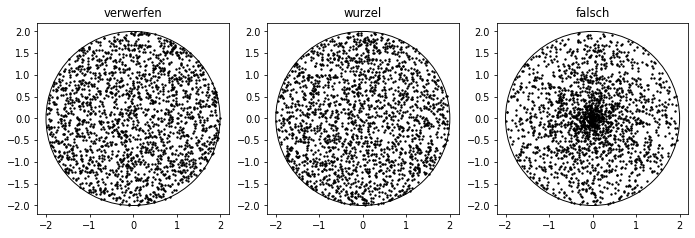

In [ ]:
fig, achsen = plt.subplots(1, 3, figsize=(12, 4))
for achse, name in zip(achsen, ['verwerfen', 'wurzel', 'falsch']):
    zufall = random.Random(2)
    punkte = []
    for i in range(2000):
        if name == 'verwerfen':
            punkte.append(punkt_verwerfen(2, zufall))
        elif name == 'wurzel':
            punkte.append(punkt_wurzel(2, zufall))
        else:
            punkte.append(punkt_falsch(2, zufall))
    achse.add_patch(Circle((0, 0), 2, fill=False))
    achse.scatter([p[0] for p in punkte], [p[1] for p in punkte], s=2, color='black')
    achse.set_aspect('equal')
    achse.set_title(name)
plt.show()

## Schritt 2: Welche Kegel trifft ein Wurf?

Ein Wurf ist bei uns ein Tripel `(x, y, winkel)`: Die Bahn geht durch den Punkt `(x, y)` in Richtung `winkel` (in Grad, gemessen
gegen den Uhrzeigersinn von der x-Achse). Ob die Kugel von links oder von rechts kommt, ist egal: Winkel `w` und `w + 180°` treffen
dieselben Kegel.

Die Richtung der Bahn ist `(cos w, sin w)`, die **Normale** `(nx, ny) = (−sin w, cos w)` steht senkrecht darauf und hat die Länge 1.
Für jeden Punkt gibt `lage = x·nx + y·ny` an, wie weit er quer zur Bahn liegt. Alle Punkte der Bahn haben dieselbe Lage `mitte`. Ein
Kegel hat von der Bahn also den Abstand `|lage − mitte|` und wird getroffen, wenn dieser höchstens 1 ist. (Die Lösungshinweise nennen
das „Kegel-Erfassung durch Drehung“: Man dreht alles, bis die Bahn waagerecht liegt, dann zählt nur noch die y-Koordinate.)

In [ ]:
def treffer(kegel, wurf):
    """Liste der Nummern aller Kegel, die der Wurf (x, y, winkel) trifft."""
    x, y, winkel = wurf
    w = math.radians(winkel)
    nx = -math.sin(w)                  # Normale: senkrecht zur Bahn, Länge 1
    ny = math.cos(w)
    mitte = x * nx + y * ny            # Lage der Bahn quer zu ihrer Richtung
    liste = []
    for i in range(len(kegel)):
        kx, ky = kegel[i]
        if abs(kx * nx + ky * ny - mitte) <= 1:
            liste.append(i)
    return liste


def entferne(kegel, liste):
    """Die Kegel ohne die getroffenen."""
    rest = []
    for i in range(len(kegel)):
        if i not in liste:
            rest.append(kegel[i])
    return rest


klein, R_klein = lies_kegel('eigene_testdaten/klein.txt')
print(klein)
for wurf in [(0, 0, 0), (0, 0, 90), (0, 0, 45), (0, 0, 225), (0, -1, 0)]:
    print('Wurf', wurf, 'trifft', treffer(klein, wurf))

[(0.0, 0.0), (0.9, 0.5), (-1.5, 0.9), (0.5, -1.2), (1.8, -0.3)]
Wurf (0, 0, 0) trifft [0, 1, 2, 4]
Wurf (0, 0, 90) trifft [0, 1, 3]
Wurf (0, 0, 45) trifft [0, 1]
Wurf (0, 0, 225) trifft [0, 1]
Wurf (0, -1, 0) trifft [0, 3, 4]


Nachrechnen: Der waagerechte Wurf durch den Mittelpunkt trifft alle Kegel mit `|y| ≤ 1`, also alle außer `(0.5, −1.2)`. Der
senkrechte trifft die mit `|x| ≤ 1`. Bei 45° ist der Abstand `|y − x| / √2`; das ist nur für `(0, 0)` und `(0.9, 0.5)` höchstens 1.
225° ist dieselbe Gerade wie 45°. Die waagerechte Bahn durch `(0, −1)` trifft alles mit `−2 ≤ y ≤ 0`.

## Schritt 3: Spielfeld und Wurf zeichnen

Die Bahn zeichnen wir als langes, schmales Rechteck (Breite 2), das am Kreis abgeschnitten wird (`set_clip_path`). Getroffene Kegel
bekommen ein farbiges Kreuz, die anderen einen schwarzen Punkt. Die Achsen bleiben sichtbar, damit man Koordinaten für den eigenen
Wurf ablesen kann.

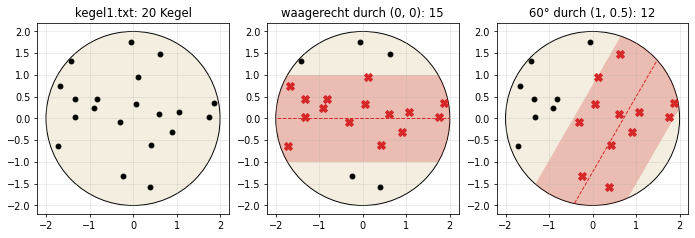

In [ ]:
def zeichne(achse, R, kegel, wurf=None, farbe='tab:red', titel=''):
    feld = Circle((0, 0), R, facecolor='#f3eedf', edgecolor='black')
    achse.add_patch(feld)
    liste = []
    if wurf is not None:
        x, y, winkel = wurf
        w = math.radians(winkel)
        tx, ty = math.cos(w), math.sin(w)            # Richtung der Bahn
        nx, ny = -ty, tx                             # Normale
        L = 3 * R                                    # lang genug, um über den Kreis hinauszuragen
        ecken = [(x - L * tx + nx, y - L * ty + ny), (x + L * tx + nx, y + L * ty + ny),
                 (x + L * tx - nx, y + L * ty - ny), (x - L * tx - nx, y - L * ty - ny)]
        bahn = Polygon(ecken, facecolor=farbe, alpha=0.25, edgecolor='none')
        achse.add_patch(bahn)
        bahn.set_clip_path(feld)
        mittellinie = achse.plot([x - L * tx, x + L * tx], [y - L * ty, y + L * ty], '--', color=farbe, linewidth=1)[0]
        mittellinie.set_clip_path(feld)
        liste = treffer(kegel, wurf)
    for i in range(len(kegel)):
        if i in liste:
            achse.plot(kegel[i][0], kegel[i][1], 'X', color=farbe, markersize=9)
        else:
            achse.plot(kegel[i][0], kegel[i][1], 'o', color='black', markersize=5)
    achse.set_xlim(-R - 0.2, R + 0.2)
    achse.set_ylim(-R - 0.2, R + 0.2)
    achse.set_aspect('equal')
    achse.grid(alpha=0.3)
    achse.set_title(titel)


fig, achsen = plt.subplots(1, 3, figsize=(12, 4))
zeichne(achsen[0], R1, kegel1, titel='kegel1.txt: 20 Kegel')
zeichne(achsen[1], R1, kegel1, (0, 0, 0), titel='waagerecht durch (0, 0): %d' % len(treffer(kegel1, (0, 0, 0))))
zeichne(achsen[2], R1, kegel1, (1, 0.5, 60), titel='60° durch (1, 0.5): %d' % len(treffer(kegel1, (1, 0.5, 60))))
plt.show()

## Schritt 4: Randy

Randy zieht einen Punkt in der Kreisscheibe (mit der Wurzel-Methode) und einen Winkel zwischen 0° und 360°.

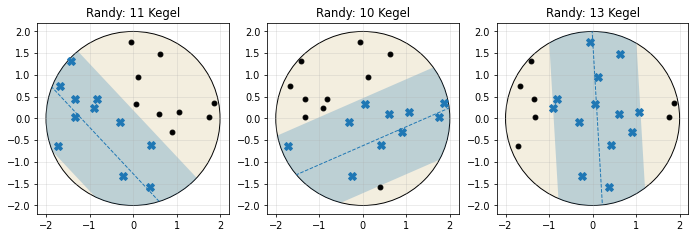

In [ ]:
def randy_wurf(R, zufall):
    x, y = punkt_wurzel(R, zufall)
    winkel = zufall.uniform(0, 360)
    return (x, y, winkel)


zufall = random.Random(3)
fig, achsen = plt.subplots(1, 3, figsize=(12, 4))
for achse in achsen:
    wurf = randy_wurf(R1, zufall)
    zeichne(achse, R1, kegel1, wurf, 'tab:blue', 'Randy: %d Kegel' % len(treffer(kegel1, wurf)))
plt.show()

## Schritt 5: Anna spielt gegen Randy

Ohne Maus und ohne `input()` (das klappt im Browser-Notebook nicht gut) spielt Anna mit drei Befehlen:

- `neues_spiel(N, R)` beginnt ein Spiel. Randy wirft sofort die erste Kugel der ersten Runde.
- `vorschau(x, y, winkel)` zeichnet den geplanten Wurf und zeigt, welche Kegel er treffen würde. Es passiert noch nichts.
- `wirf(x, y, winkel)` führt den Wurf aus. Danach wirft Randy, und beide Würfe werden nebeneinander gezeichnet.
  Mit `wirf(x, y, winkel, beenden=True)` beendet Anna die Runde nach ihrem Wurf.

Nach jedem Wurf steht der Stand der Runde und des ganzen Spiels da. Ist kein Kegel mehr übrig (oder hat Anna beendet), beginnt
sofort die nächste Runde, wieder mit Randys Wurf. Alles, was sich das Spiel merken muss, steht im Dictionary `spiel`.

Runde 1: Anna 0, Randy 14, noch 6 Kegel  |  insgesamt: Anna 0, Randy 14


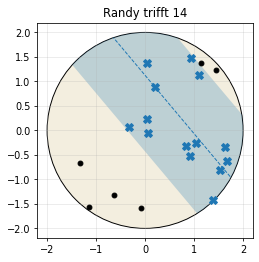

In [ ]:
spiel = {}


def neues_spiel(N=20, R=2, seed=None):
    spiel['N'] = N
    spiel['R'] = R
    spiel['zufall'] = random.Random(seed)
    spiel['anna'] = 0                  # Punkte über alle Runden
    spiel['randy'] = 0
    spiel['runde'] = 0
    neue_runde()


def melde():
    print('Runde %d: Anna %d, Randy %d, noch %d Kegel  |  insgesamt: Anna %d, Randy %d' %
          (spiel['runde'], spiel['anna_runde'], spiel['randy_runde'], len(spiel['kegel']), spiel['anna'], spiel['randy']))


def randy_ist_dran(achse):
    wurf = randy_wurf(spiel['R'], spiel['zufall'])
    liste = treffer(spiel['kegel'], wurf)
    zeichne(achse, spiel['R'], spiel['kegel'], wurf, 'tab:blue', 'Randy trifft %d' % len(liste))
    spiel['randy'] += len(liste)
    spiel['randy_runde'] += len(liste)
    spiel['kegel'] = entferne(spiel['kegel'], liste)


def neue_runde():
    spiel['runde'] += 1
    spiel['anna_runde'] = 0
    spiel['randy_runde'] = 0
    spiel['kegel'] = aufstellen(spiel['N'], spiel['R'], spiel['zufall'])
    fig, achse = plt.subplots(figsize=(4, 4))
    randy_ist_dran(achse)              # Randy wirft immer zuerst
    plt.show()
    melde()
    if len(spiel['kegel']) == 0:
        print('Randy hat alles abgeräumt.')
        neue_runde()


def vorschau(x, y, winkel):
    wurf = (x, y, winkel)
    fig, achse = plt.subplots(figsize=(4, 4))
    zeichne(achse, spiel['R'], spiel['kegel'], wurf, 'tab:red', 'Vorschau: %d Kegel' % len(treffer(spiel['kegel'], wurf)))
    plt.show()


def wirf(x, y, winkel, beenden=False):
    wurf = (x, y, winkel)
    liste = treffer(spiel['kegel'], wurf)
    fig, achsen = plt.subplots(1, 2, figsize=(8, 4))
    zeichne(achsen[0], spiel['R'], spiel['kegel'], wurf, 'tab:red', 'Anna trifft %d' % len(liste))
    spiel['anna'] += len(liste)
    spiel['anna_runde'] += len(liste)
    spiel['kegel'] = entferne(spiel['kegel'], liste)
    if len(spiel['kegel']) > 0 and not beenden:
        randy_ist_dran(achsen[1])
    else:
        achsen[1].axis('off')
    plt.show()
    melde()
    if len(spiel['kegel']) == 0 or beenden:
        print('Runde %d ist zu Ende.' % spiel['runde'])
        neue_runde()


neues_spiel(N=20, R=2, seed=5)

Randy hat angefangen. Anna sieht sich das Bild an und plant einen Wurf. Mit `vorschau` probiert sie ihn aus:

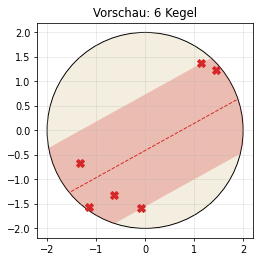

In [ ]:
vorschau(0.2, -0.3, 29)

Das sieht gut aus, also wirft sie. Randy antwortet sofort:

Runde 1: Anna 6, Randy 14, noch 0 Kegel  |  insgesamt: Anna 6, Randy 14
Runde 1 ist zu Ende.
Runde 2: Anna 0, Randy 6, noch 14 Kegel  |  insgesamt: Anna 6, Randy 20


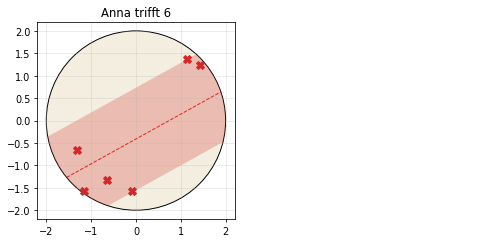

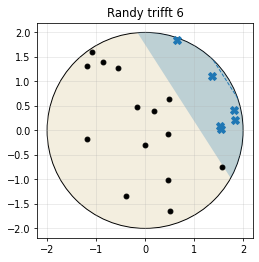

In [ ]:
wirf(0.2, -0.3, 29)

So kann man weiterspielen, bis man genug hat: `vorschau` und `wirf` mit neuen Zahlen aufrufen, die man aus dem Bild abliest. In
Schritt 12 lassen wir Anna mit `anna_automatisch()` von selbst werfen.

## Schritt 6: Wie viel trifft Randy?

Bevor wir eine Strategie suchen, müssen wir wissen, wie stark Randy ist. Die wichtigste Zahl ist `q`: der Anteil der Kegel, den ein
zufälliger Wurf im Mittel trifft. Bei Randys erstem Wurf stehen noch alle N Kegel, er trifft also im Mittel `q · N`.

**Erst simulieren:** Wir stellen 200.000-mal einen einzelnen Kegel auf und lassen Randy werfen.

In [ ]:
zufall = random.Random(4)
versuche = 200000
getroffen = 0
for i in range(versuche):
    ein_kegel = [punkt_wurzel(2, zufall)]
    if len(treffer(ein_kegel, randy_wurf(2, zufall))) == 1:
        getroffen += 1
print('Randy trifft %.2f %% der Kegel' % (100 * getroffen / versuche))

Randy trifft 49.74 % der Kegel


Etwa die Hälfte. Ob es knapp mehr oder knapp weniger als die Hälfte ist, entscheidet, ob Anna überhaupt gewinnen kann (siehe unten).
Für so eine Frage ist die Simulation zu ungenau (sie schwankt um etwa ±0,1 Prozentpunkte). Wir rechnen `q` deshalb aus.

**Dann rechnen:** Weil der Kreis rund ist, ist die Richtung egal; wir denken uns Randys Wurf waagerecht. Er trifft dann alle Kegel,
deren y-Wert höchstens 1 vom y-Wert seines Punktes abweicht. Wir brauchen den Anteil der Kreisfläche unterhalb einer waagerechten
Geraden `y = s`. Die Formel für einen Kreisabschnitt (Formelsammlung) gibt

`anteil_unter(s) = (R² · (arcsin(s/R) + π/2) + s · √(R² − s²)) / (π R²)`   für −R ≤ s ≤ R.

Randys Bahn mit y-Wert `s` trifft also den Anteil `anteil_unter(s + 1) − anteil_unter(s − 1)`. Wir zerlegen den Kreis in 2000
waagerechte Streifen: Randys Punkt liegt mit Wahrscheinlichkeit `anteil_unter(oben) − anteil_unter(unten)` in einem Streifen, und
dann trifft er den Anteil von oben. Aufsummieren ergibt `q`.

Dieselbe Formel liefert auch die **Trefferchance eines einzelnen Kegels** im Abstand `rho` vom Mittelpunkt: Für die Wurfrichtung
`w` liegt der Kegel quer zur Bahn bei `rho · sin w`, und Randys Punkt hat (wie jeder Zufallspunkt im Kreis) quer zur Bahn die Verteilung
`anteil_unter`. Wir mitteln über 360 Richtungen. Diese Chance brauchen wir später für Annas klügere Strategie.

In [ ]:
def anteil_unter(s, R):
    """Anteil der Kreisfläche unterhalb der waagerechten Geraden y = s."""
    if s <= -R:
        return 0.0
    if s >= R:
        return 1.0
    return (R * R * (math.asin(s / R) + math.pi / 2) + s * math.sqrt(R * R - s * s)) / (math.pi * R * R)


def randy_anteil(R, streifen=2000):
    """q: welcher Anteil der Kegel im Mittel von einem Zufallswurf getroffen wird."""
    q = 0
    for i in range(streifen):
        unten = -R + 2 * R * i / streifen
        oben = -R + 2 * R * (i + 1) / streifen
        s = (unten + oben) / 2                                   # Randys Punkt liegt in diesem Streifen
        wahrscheinlichkeit = anteil_unter(oben, R) - anteil_unter(unten, R)
        q += wahrscheinlichkeit * (anteil_unter(s + 1, R) - anteil_unter(s - 1, R))
    return q


def trefferchance(rho, R, richtungen=360):
    """Wahrscheinlichkeit, dass Randy einen Kegel im Abstand rho vom Mittelpunkt trifft."""
    summe = 0
    for i in range(richtungen):
        w = 2 * math.pi * (i + 0.5) / richtungen
        s = rho * math.sin(w)                                    # Lage des Kegels quer zur Bahn
        summe += anteil_unter(s + 1, R) - anteil_unter(s - 1, R)
    return summe / richtungen


q2 = randy_anteil(2)
print('q(2) = %.4f, Randy trifft also %.2f %% der Kegel' % (q2, 100 * q2))
print('Trefferchance in der Mitte: %.3f, am Rand: %.3f' % (trefferchance(0, 2), trefferchance(2, 2)))

# Probe: Mittelwert der Trefferchance über alle Stellen des Kreises (Ringe gleicher Fläche) muss wieder q sein
ringe = 1000
mittel_chancen = 0
for i in range(ringe):
    mittel_chancen += trefferchance(2 * math.sqrt((i + 0.5) / ringe), 2, 120) / ringe
print('Mittel der Trefferchancen: %.4f' % mittel_chancen)

q(2) = 0.4966, Randy trifft also 49.66 % der Kegel
Trefferchance in der Mitte: 0.609, am Rand: 0.390
Mittel der Trefferchancen: 0.4966


`q(2) = 0,4966`: Randy trifft mit seinem ersten Wurf im Mittel 49,66 % der Kegel, genau wie in den Lösungshinweisen. Kegel in der
Mitte trifft er viel öfter als Kegel am Rand.

Wie hängt `q` vom Radius ab? Je größer das Feld, desto kleiner der Anteil, den die Bahn der Breite 2 überdeckt. Wo genau ist
`q = 1/2`? `q` wird mit wachsendem R kleiner, also können wir die Stelle durch **Bisektion** einschachteln: Ist `q` in der Mitte des
Intervalls noch größer als 1/2, liegt die gesuchte Stelle rechts davon, sonst links.

q = 1/2 bei R = 1.984


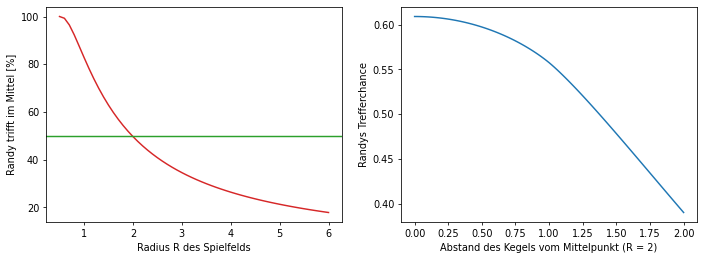

In [ ]:
links, rechts = 1.5, 2.5
for schritt in range(30):
    mitte_R = (links + rechts) / 2
    if randy_anteil(mitte_R, 500) > 0.5:
        links = mitte_R
    else:
        rechts = mitte_R
R_halb = (links + rechts) / 2
print('q = 1/2 bei R = %.3f' % R_halb)

radien = [0.5 + 0.1 * i for i in range(56)]
fig, achsen = plt.subplots(1, 2, figsize=(12, 4))
achsen[0].plot(radien, [100 * randy_anteil(r, 500) for r in radien], color='tab:red')
achsen[0].axhline(50, color='tab:green')
achsen[0].set_xlabel('Radius R des Spielfelds')
achsen[0].set_ylabel('Randy trifft im Mittel [%]')
abstaende = [i / 50 for i in range(101)]
achsen[1].plot(abstaende, [trefferchance(a, 2) for a in abstaende], color='tab:blue')
achsen[1].set_xlabel('Abstand des Kegels vom Mittelpunkt (R = 2)')
achsen[1].set_ylabel('Randys Trefferchance')
plt.show()

Das linke Bild entspricht Abbildung 3 der Lösungshinweise. Ab R ≈ 1,984 trifft Randy weniger als die Hälfte.

**Was heißt das für Anna?** In einer Runde trifft Randy mit dem ersten Wurf im Mittel `q · N` Kegel. Anna kann in dieser Runde höchstens
alle übrigen bekommen, also im Mittel höchstens `(1 − q) · N`. Randy bekommt mindestens seine `q · N`. Damit gilt für **jede**
Strategie:

- Annas Punkte geteilt durch Randys Punkte sind auf lange Sicht höchstens `(1 − q) / q`.
- Annas Vorsprung je Runde ist höchstens `N · (1 − 2q)`.

Für R < 1,984 ist `q > 1/2`, dann **kann Anna nicht gewinnen**, egal wie gut sie spielt. Bei R = 2 ist die Schranke 1,0136: Anna kann
höchstens 1,4 % mehr Punkte holen als Randy, und auch das nur, wenn sie nach Randys erstem Wurf **immer alle** übrigen Kegel mit
einem Wurf abräumt.

In [ ]:
for R in [1.5, 2, 2.25, 3]:
    q = randy_anteil(R)
    print('R = %4.2f: q = %.4f, Anna / Randy höchstens %.4f' % (R, q, (1 - q) / q))

R = 1.50: q = 0.6287, Anna / Randy höchstens 0.5906
R = 2.00: q = 0.4966, Anna / Randy höchstens 1.0136
R = 2.25: q = 0.4482, Anna / Randy höchstens 1.2312
R = 3.00: q = 0.3452, Anna / Randy höchstens 1.8967


## Schritt 7: Annas erste Strategie – die beste von 100 Zufallswürfen

Die einfachste Idee: Anna probiert (im Kopf) 100 Würfe wie Randy aus und nimmt den, der die meisten Kegel trifft. Die Lösungshinweise
nennen das „Randy*100“.

In [ ]:
def wurf_randy100(kegel, R, zufall):
    bester = None
    beste_zahl = -1
    for i in range(100):
        wurf = randy_wurf(R, zufall)
        zahl = len(treffer(kegel, wurf))
        if zahl > beste_zahl:
            bester = wurf
            beste_zahl = zahl
    return bester

## Schritt 8: Die zweite Strategie – der Wurf mit den meisten Treffern

Besser ist es, wirklich den besten Wurf zu suchen. Für einen festen Winkel hängt der Wurf nur noch davon ab, wo die Bahn quer zu ihrer
Richtung liegt. Wir berechnen für jeden Kegel seine `lage` auf der Normalen und sortieren diese Zahlen. Gesucht ist ein Intervall der
Länge 2 mit möglichst vielen Zahlen darin.

**Gleitendes Fenster:** Der rechte Zeiger `i` läuft durch die sortierte Liste. Der linke Zeiger `j` rückt nach, solange
`lage[i] − lage[j] > 2` ist. Dann liegen genau die Kegel `j` bis `i` in einem Fenster der Breite 2, das sind `i − j + 1` Stück. Jeder
Zeiger läuft nur einmal durch die Liste.

Die Bahn legen wir genau in die Mitte zwischen `lage[j]` und `lage[i]`. So liegt kein Kegel genau auf dem Rand der Bahn, wo Rundungsfehler
entscheiden würden, ob er getroffen wird. Der Punkt der Bahn ist dann `mitte · (nx, ny)`.

Wir probieren alle ganzen Winkel von 0° bis 179° (die Lösungshinweise sagen, dass ganze Winkel ausreichen; auch der Turnierserver
rechnet so). Ob dabei manchmal der beste Wurf zwischen zwei ganzen Winkeln liegt, prüfen wir unter „Für Neugierige“: Das kommt
selten vor.

kegel1.txt (N = 20, R = 2): bester Wurf (0.000, 0.340, 0°) trifft 16 Kegel
kegel2.txt (N = 10, R = 2): bester Wurf (0.000, 0.347, 0°) trifft 7 Kegel
kegel3.txt (N = 10, R = 3): bester Wurf (-0.117, 0.666, 10°) trifft 7 Kegel
kegel4.txt (N = 50, R = 3): bester Wurf (0.397, 0.042, 96°) trifft 28 Kegel


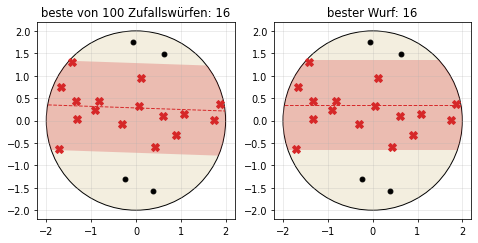

In [ ]:
def bester_wurf(kegel):
    """Der Wurf mit den meisten Treffern unter allen ganzen Winkeln 0 bis 179 Grad."""
    beste_zahl = 0
    bester = None
    for winkel in range(180):
        w = math.radians(winkel)
        nx, ny = -math.sin(w), math.cos(w)
        lage = []
        for kx, ky in kegel:
            lage.append(kx * nx + ky * ny)
        lage.sort()
        j = 0
        for i in range(len(lage)):
            while lage[i] - lage[j] > 2:
                j += 1
            if i - j + 1 > beste_zahl:
                beste_zahl = i - j + 1
                mitte = (lage[i] + lage[j]) / 2
                bester = (mitte * nx, mitte * ny, winkel)
    return bester


for nr in [1, 2, 3, 4]:
    kegel, R = lies_kegel('beispieldaten/kegel%d.txt' % nr)
    wurf = bester_wurf(kegel)
    print('kegel%d.txt (N = %2d, R = %g): bester Wurf (%.3f, %.3f, %d°) trifft %d Kegel' %
          (nr, len(kegel), R, round(wurf[0], 3) + 0.0, round(wurf[1], 3) + 0.0, wurf[2], len(treffer(kegel, wurf))))

zufall = random.Random(6)
fig, achsen = plt.subplots(1, 2, figsize=(8, 4))
wurf = wurf_randy100(kegel1, R1, zufall)
zeichne(achsen[0], R1, kegel1, wurf, titel='beste von 100 Zufallswürfen: %d' % len(treffer(kegel1, wurf)))
wurf = bester_wurf(kegel1)
zeichne(achsen[1], R1, kegel1, wurf, titel='bester Wurf: %d' % len(treffer(kegel1, wurf)))
plt.show()

## Schritt 9: Viele Runden simulieren – und richtig messen

Eine Runde ohne Bilder: Randy wirft, dann abwechselnd Anna und Randy, bis kein Kegel mehr steht oder Anna die Runde beendet. Welche
Strategie Anna spielt, steht in der Variablen `ANNA`; die Funktion `annas_wurf` schaut dort nach. (So können wir die Strategie
wechseln, ohne die Funktion `runde` zu ändern.) Die Funktion gibt Annas Punkte, Randys Punkte aus dem ersten Wurf, Randys spätere
Punkte und die Zahl der Kegel zurück, die am Ende noch stehen.

In [ ]:
ANNA = 'bester'


def annas_wurf(kegel, R, zufall):
    if ANNA == 'randy100':
        return wurf_randy100(kegel, R, zufall)
    return bester_wurf(kegel)


def anna_beendet(kegel, R):
    return False                       # bisher spielt Anna jede Runde zu Ende


def runde(N, R, zufall):
    kegel = aufstellen(N, R, zufall)
    liste = treffer(kegel, randy_wurf(R, zufall))
    randy_erster = len(liste)
    kegel = entferne(kegel, liste)
    anna = 0
    randy_spaeter = 0
    while len(kegel) > 0:
        liste = treffer(kegel, annas_wurf(kegel, R, zufall))
        anna += len(liste)
        kegel = entferne(kegel, liste)
        if len(kegel) == 0 or anna_beendet(kegel, R):
            break
        liste = treffer(kegel, randy_wurf(R, zufall))
        randy_spaeter += len(liste)
        kegel = entferne(kegel, liste)
    return anna, randy_erster, randy_spaeter, len(kegel)


print(runde(20, 2, random.Random(1)))

(14, 3, 3, 0)


**Das Problem mit dem Zählen.** Man könnte einfach viele Runden spielen, Annas und Randys Punkte addieren und teilen. Das ist aber sehr
ungenau: Randys erster Wurf trifft bei 20 Kegeln mal 3, mal 14 Kegel, und dieses Glück überdeckt alles andere. Die Unterschiede
zwischen den Strategien liegen dagegen bei 1 bis 2 %.

**Der Trick.** In jeder Runde gilt `Anna + Randy_erster + Randy_später + Rest = N`, also

`Anna − Randy = N − 2 · Randy_erster − (2 · Randy_später + Rest)`.

Den Erwartungswert von `Randy_erster` kennen wir genau: `q · N`. Wir müssen also nur noch den **Verlust**
`2 · Randy_später + Rest` messen: Das sind die Kegel, die Anna nach Randys erstem Wurf nicht selbst bekommt, Randys doppelt gezählt
(er bekommt sie, und Anna nicht). Annas mittlerer **Vorsprung je Runde** ist dann

`Vorsprung = N · (1 − 2q) − mittlerer Verlust`,

und Anna gewinnt genau dann, wenn ihr mittlerer Verlust kleiner als `N · (1 − 2q)` ist (bei R = 2 und N = 20: 0,135 Kegel je Runde).
Räumt Anna meistens alles ab, ist der Verlust meistens 0 und schwankt viel weniger als Randys erster Wurf. Das Verhältnis
„Anna / Randy“ der Lösungshinweise berechnen wir daraus mit `Randy = q · N + mittleres Randy_später`.

**Unsicherheit.** Ein Mittelwert aus `n` Runden schwankt ungefähr um `s / √n`, wobei `s` die Standardabweichung der einzelnen Werte
ist. Als Faustregel ist ein Unterschied erst dann echt, wenn er größer als die doppelte Unsicherheit ist.

Jede Runde bekommt ihren eigenen Zufallsgenerator mit der Startzahl `seed · 100000 + Rundennummer`. So spielen verschiedene
Strategien gegen dieselben Aufstellungen und denselben ersten Wurf von Randy, und Vergleiche werden fairer.

In [ ]:
def messen(N, R, runden, seed=1):
    q = randy_anteil(R)
    verluste = []
    summe_spaeter = 0
    summe_anna = 0
    summe_randy = 0
    beendet = 0
    for r in range(runden):
        anna, randy_erster, randy_spaeter, rest = runde(N, R, random.Random(seed * 100000 + r))
        verluste.append(2 * randy_spaeter + rest)
        summe_spaeter += randy_spaeter
        summe_anna += anna
        summe_randy += randy_erster + randy_spaeter
        if rest > 0:
            beendet += 1
    verlust = sum(verluste) / runden
    streuung = 0
    for v in verluste:
        streuung += (v - verlust) ** 2
    unsicher = math.sqrt(streuung / runden) / math.sqrt(runden)
    vorsprung = N * (1 - 2 * q) - verlust
    randy = q * N + summe_spaeter / runden                   # Randys Punkte je Runde (erster Wurf genau gerechnet)
    return {'vorsprung': vorsprung, 'unsicher': unsicher,
            'verhaeltnis': (randy + vorsprung) / randy, 'verh_unsicher': unsicher / randy,
            'gezaehlt': summe_anna / summe_randy, 'beendet': beendet, 'verluste': verluste}


ANNA = 'bester'
print('N = 20, R = 2, je 400 Runden:')
for seed in range(1, 6):
    m = messen(20, 2, 400, seed)
    print('  gezählt: Anna / Randy = %.3f    mit dem Trick: %.3f ± %.3f' %
          (m['gezaehlt'], m['verhaeltnis'], m['verh_unsicher']))

N = 20, R = 2, je 400 Runden:
  gezählt: Anna / Randy = 0.956    mit dem Trick: 0.974 ± 0.004
  gezählt: Anna / Randy = 0.962    mit dem Trick: 0.979 ± 0.004
  gezählt: Anna / Randy = 0.992    mit dem Trick: 0.975 ± 0.005
  gezählt: Anna / Randy = 0.960    mit dem Trick: 0.973 ± 0.005
  gezählt: Anna / Randy = 0.950    mit dem Trick: 0.978 ± 0.004


Die gezählten Verhältnisse springen zwischen den fünf Messungen viel stärker hin und her als die mit dem Trick berechneten. Jetzt
vergleichen wir die beiden Strategien für R = 2.

In [ ]:
for N in [5, 10, 20]:
    for name in ['randy100', 'bester']:
        ANNA = name
        m = messen(N, 2, 1500)
        print('N = %2d, %-8s: Vorsprung je Runde %+.3f ± %.3f, Anna / Randy = %.4f ± %.4f' %
              (N, name, m['vorsprung'], m['unsicher'], m['verhaeltnis'], m['verh_unsicher']))

N =  5, randy100: Vorsprung je Runde +0.014 ± 0.005, Anna / Randy = 1.0055 ± 0.0021
N =  5, bester  : Vorsprung je Runde +0.027 ± 0.003, Anna / Randy = 1.0109 ± 0.0012
N = 10, randy100: Vorsprung je Runde -0.099 ± 0.015, Anna / Randy = 0.9803 ± 0.0029
N = 10, bester  : Vorsprung je Runde -0.006 ± 0.010, Anna / Randy = 0.9988 ± 0.0019
N = 20, randy100: Vorsprung je Runde -0.469 ± 0.030, Anna / Randy = 0.9542 ± 0.0029
N = 20, bester  : Vorsprung je Runde -0.243 ± 0.022, Anna / Randy = 0.9760 ± 0.0022


**Ergebnis:**
- Die beste von 100 Zufallswürfen ist deutlich schlechter als der beste Wurf; bei 10 und 20 Kegeln verliert sie klar.
- Mit dem besten Wurf gewinnt Anna bei 5 Kegeln. Bei 10 Kegeln ist das Spiel fast ausgeglichen (dazu gleich mehr), bei **20 Kegeln
  verliert Anna**.

**Warum?** Gewinnen kann Anna nur, wenn sie nach Randys erstem Wurf fast immer alle übrigen Kegel auf einmal abräumt. Wie oft geht das
überhaupt? Wir stellen Kegel auf, lassen Randy werfen und prüfen, ob der beste Wurf alle übrigen trifft. Daraus wird eine
**Schranke für jede Strategie**: Kann Anna nicht alles abräumen, bleibt mindestens ein Kegel stehen. Beendet sie die Runde, verliert sie
ihn (Verlust mindestens 1). Spielt sie weiter, trifft Randy jeden stehenden Kegel mindestens mit der Chance eines Kegels am Rand,
`trefferchance(2, 2)` = 0,39, und jeder seiner Treffer zählt doppelt (Verlust im Mittel mindestens 0,78). Also ist der mittlere
Verlust mindestens `0,78 · (Anteil der Runden, in denen Abräumen unmöglich ist)`, und Annas Vorsprung je Runde höchstens
`N · (1 − 2q) − 0,78 · Anteil`.

In [ ]:
rand = trefferchance(2, 2)
for N in [5, 10, 20, 50]:
    alle = 0
    for r in range(1000):
        zufall = random.Random(r)
        kegel = aufstellen(N, 2, zufall)
        kegel = entferne(kegel, treffer(kegel, randy_wurf(2, zufall)))
        if len(kegel) == 0 or len(treffer(kegel, bester_wurf(kegel))) == len(kegel):
            alle += 1
    unmoeglich = 1 - alle / 1000
    print('N = %2d: Abräumen möglich in %5.1f %% der Runden, Vorsprung jeder Strategie höchstens %+.3f' %
          (N, alle / 10, N * (1 - 2 * q2) - 2 * rand * unmoeglich))

N =  5: Abräumen möglich in  99.5 % der Runden, Vorsprung jeder Strategie höchstens +0.030
N = 10: Abräumen möglich in  91.9 % der Runden, Vorsprung jeder Strategie höchstens +0.004
N = 20: Abräumen möglich in  65.9 % der Runden, Vorsprung jeder Strategie höchstens -0.131
N = 50: Abräumen möglich in  27.5 % der Runden, Vorsprung jeder Strategie höchstens -0.229


Bei 20 Kegeln geht das nur in etwa zwei von drei Runden. Schon das kostet mehr, als Annas Spielraum von 0,135 Kegeln je Runde hergibt:
Der Vorsprung **jeder** Strategie ist negativ, Anna kann bei N = 20 und R = 2 nicht gewinnen. Bei N = 10 lässt die Schranke noch einen
winzigen Gewinn zu, bei N = 5 einen kleinen. Zwei Feinheiten: Der Anteil ist aus 1000 Zufallsaufstellungen geschätzt (Unsicherheit etwa
1,5 Prozentpunkte), und mit ganzen Winkeln verpasst `bester_wurf` selten den besten Wurf (unter „Für Neugierige“: in etwa 1 % der
Aufstellungen). Beides ist viel zu klein, um das Vorzeichen bei N = 20 zu ändern.

Die Schranke ist eine **obere** Grenze: Oft bleiben mehrere Kegel stehen, und meistens nicht alle am Rand, wo Randy am schlechtesten
trifft. Deshalb verliert Anna mit dem besten Wurf noch mehr (Vorsprung etwa −0,2 statt −0,13).

## Schritt 10: Die dritte Strategie – an Randys nächsten Wurf denken

Kann Anna nicht alles abräumen, sollte sie lieber Kegel stehen lassen, die Randy schlecht trifft, also die am Rand (Schritt 6:
Trefferchance in der Mitte 0,61, am Rand 0,39). Mit dem Verlust aus Schritt 9 können wir das genau fassen. Bleiben nach Annas Wurf
die Kegel `S` stehen, dann

- kostet **Beenden** genau `|S|` (die Kegel sind für Anna verloren),
- kostet **Weiterspielen** mindestens `2 · (Summe der Trefferchancen in S)`, denn so viele Kegel bekommt Randy im Mittel mit dem
  nächsten Wurf, und jeder zählt doppelt. Danach kann Anna im besten Fall den Rest abräumen.

Anna wählt deshalb den Wurf, für den `min(|S|, 2 · Summe der Chancen in S)` am kleinsten ist, und beendet die Runde, wenn
`|S| < 2 · Summe der Chancen` ist, also wenn die übrigen Kegel für Randy im Mittel besser als halb zu treffen sind. Ein einzelner
Kegel in der Mitte (Chance 0,61) ist so ein Fall: Weiterspielen kostet im Mittel 1,22 Kegel, Beenden nur 1.

Für jeden Kegel brauchen wir seine Trefferchance. Damit das schnell geht, berechnen wir sie einmal für 101 Abstände und schauen dann
nur noch in der Tabelle nach (`CHANCEN` merkt sich die Tabelle für jeden Radius). Neu im Fenster: Wir sortieren **Paare**
`(lage, chance)`. Python sortiert Paare nach dem ersten Eintrag (bei Gleichstand nach dem zweiten), die Chance wandert also mit ihrem
Kegel mit. Im Fenster zählen wir die Kegel und addieren ihre Chancen.

In [ ]:
CHANCEN = {}


def chance(kx, ky, R):
    if R not in CHANCEN:
        tabelle = []
        for i in range(101):
            tabelle.append(trefferchance(R * i / 100, R))
        CHANCEN[R] = tabelle
    return CHANCEN[R][round(math.hypot(kx, ky) / R * 100)]


def kluger_wurf(kegel, R):
    """Der Wurf, nach dem die übrigen Kegel S am wenigsten kosten: min(|S|, 2 * Summe ihrer Chancen)."""
    chancen = []
    for kx, ky in kegel:
        chancen.append(chance(kx, ky, R))
    summe_alle = sum(chancen)
    beste_kosten = len(kegel) + 1
    bester = None
    for winkel in range(180):
        w = math.radians(winkel)
        nx, ny = -math.sin(w), math.cos(w)
        paare = []
        for k in range(len(kegel)):
            paare.append((kegel[k][0] * nx + kegel[k][1] * ny, chancen[k]))
        paare.sort()
        j = 0
        summe = 0                                        # Summe der Chancen der Kegel j bis i (die getroffen werden)
        for i in range(len(paare)):
            summe += paare[i][1]
            while paare[i][0] - paare[j][0] > 2:
                summe -= paare[j][1]
                j += 1
            uebrig = len(kegel) - (i - j + 1)
            kosten = min(uebrig, 2 * (summe_alle - summe))
            if kosten < beste_kosten - 1e-9:
                beste_kosten = kosten
                mitte = (paare[i][0] + paare[j][0]) / 2
                bester = (mitte * nx, mitte * ny, winkel)
    return bester


def kluges_beenden(kegel, R):
    summe = 0
    for kx, ky in kegel:
        summe += chance(kx, ky, R)
    return len(kegel) < 2 * summe


def annas_wurf(kegel, R, zufall):
    if ANNA == 'randy100':
        return wurf_randy100(kegel, R, zufall)
    if ANNA == 'klug':
        return kluger_wurf(kegel, R)
    return bester_wurf(kegel)


def anna_beendet(kegel, R):
    if ANNA == 'klug':
        return kluges_beenden(kegel, R)
    return False


def unterschied(liste1, liste2):
    """Mittlerer Unterschied zweier Messreihen derselben Runden und seine Unsicherheit."""
    d = []
    for i in range(len(liste1)):
        d.append(liste1[i] - liste2[i])
    mittel = sum(d) / len(d)
    streuung = 0
    for x in d:
        streuung += (x - mittel) ** 2
    return mittel, math.sqrt(streuung / len(d)) / math.sqrt(len(d))


for N, runden in [(5, 3000), (10, 3000), (20, 1500)]:
    ergebnis = {}
    for name in ['bester', 'klug']:
        ANNA = name
        ergebnis[name] = messen(N, 2, runden, seed=2)
        m = ergebnis[name]
        print('N = %2d, %-6s: Vorsprung %+.4f ± %.4f, Anna / Randy = %.4f ± %.4f, %d Runden vorzeitig beendet' %
              (N, name, m['vorsprung'], m['unsicher'], m['verhaeltnis'], m['verh_unsicher'], m['beendet']))
    mittel, unsicher = unterschied(ergebnis['bester']['verluste'], ergebnis['klug']['verluste'])
    print('        klug ist um %.4f ± %.4f Kegel je Runde besser' % (mittel, unsicher))

N =  5, bester: Vorsprung +0.0250 ± 0.0024, Anna / Randy = 1.0101 ± 0.0010, 0 Runden vorzeitig beendet
N =  5, klug  : Vorsprung +0.0264 ± 0.0022, Anna / Randy = 1.0106 ± 0.0009, 0 Runden vorzeitig beendet
        klug ist um 0.0013 ± 0.0016 Kegel je Runde besser
N = 10, bester: Vorsprung -0.0106 ± 0.0071, Anna / Randy = 0.9979 ± 0.0014, 0 Runden vorzeitig beendet
N = 10, klug  : Vorsprung -0.0086 ± 0.0071, Anna / Randy = 0.9983 ± 0.0014, 2 Runden vorzeitig beendet
        klug ist um 0.0020 ± 0.0062 Kegel je Runde besser
N = 20, bester: Vorsprung -0.1999 ± 0.0224, Anna / Randy = 0.9802 ± 0.0022, 0 Runden vorzeitig beendet
N = 20, klug  : Vorsprung -0.1879 ± 0.0213, Anna / Randy = 0.9814 ± 0.0021, 13 Runden vorzeitig beendet
        klug ist um 0.0120 ± 0.0157 Kegel je Runde besser


**Ergebnis:** (`bester` beendet nie, dort steht deshalb 0.) Die kluge Strategie ist in allen drei Fällen ein wenig besser als der
beste Wurf, aber die Unterschiede sind kleiner als die doppelte Unsicherheit, also nicht sicher. Beim Erstellen dieses Notebooks haben
wir mit 10.000 Runden nachgemessen: Bei N = 10 ist die kluge Strategie um 0,008 ± 0,003 Kegel je Runde besser, ein echter, aber
winziger Unterschied. Das passt zu den Lösungshinweisen: Auch dort bringen ausgeklügelte Strategien kaum etwas. Das Beenden kommt
selten vor, weil Anna meistens schon mit ihrem ersten Wurf alles abräumt.

- **N = 5:** Anna gewinnt mit beiden Strategien und kommt nahe an die Schranke 1,0136 heran.
- **N = 10:** Das Spiel ist ziemlich genau ausgeglichen.
- **N = 20:** Anna verliert mit beiden Strategien deutlich (Verhältnis um 0,98, der Abstand zu 1 ist viele Unsicherheiten groß).

Bei der Aufgabe, also N = 20 und R = 2, kann Anna Randy **nicht** schlagen, nach der Schranke aus Schritt 9 auch mit keiner
anderen Strategie. Die Lösungshinweise kommen zum selben Schluss: Keine ihrer Strategien gewinnt bei N = 20, und „es ist daher mit an
Sicherheit grenzender Wahrscheinlichkeit keine Strategie in der Lage zu gewinnen“.

## Schritt 11: Andere Kegelzahlen und Radien

Jetzt die Tabelle für Teil 4, mit der klugen Strategie und je 1000 Runden (bei 50 Kegeln 400). In Klammern steht der Wert der
Strategie MaxPins (bester Wurf) aus den Lösungshinweisen. Bei N = 1 und N = 2 räumt Anna immer alles ab (zwei Kegel kann man
immer mit einem Wurf treffen), dann gibt es nichts zu messen: Der Wert ist genau die Schranke `(1 − q) / q`.

In [ ]:
HINWEISE = {1: [0.593, 1.017, 1.223, 1.893], 2: [0.591, 1.018, 1.234, 1.898], 5: [0.590, 1.014, 1.228, 1.854],
            10: [0.592, 1.004, 1.201, 1.730], 20: [0.590, 0.987, 1.157, 1.594], 50: [0.590, 0.954, 1.100, 1.450]}
RADIEN = [1.5, 2, 2.25, 3]
ANNA = 'klug'
tabelle = {}
for N in [1, 2, 5, 10]:
    for R in RADIEN:
        tabelle[(N, R)] = messen(N, R, 1000, seed=3)

In [ ]:
for R in RADIEN:
    tabelle[(20, R)] = messen(20, R, 1000, seed=3)
    tabelle[(50, R)] = messen(50, R, 400, seed=3)

print('Anna / Randy (in Klammern: MaxPins der Lösungshinweise)')
print('   N  ' + ''.join('        R = %-6g' % R for R in RADIEN))
for N in [1, 2, 5, 10, 20, 50]:
    zeile = '  %2d  ' % N
    for k in range(len(RADIEN)):
        zeile += '  %.3f±%.3f (%.3f)' % (tabelle[(N, RADIEN[k])]['verhaeltnis'], tabelle[(N, RADIEN[k])]['verh_unsicher'],
                                        HINWEISE[N][k])
    print(zeile)
print('Schranke' + ''.join('     %.3f          ' % ((1 - randy_anteil(R)) / randy_anteil(R)) for R in RADIEN))

Anna / Randy (in Klammern: MaxPins der Lösungshinweise)
   N          R = 1.5           R = 2             R = 2.25          R = 3     
   1    0.591±0.000 (0.593)  1.014±0.000 (1.017)  1.231±0.000 (1.223)  1.897±0.000 (1.893)
   2    0.591±0.000 (0.591)  1.014±0.000 (1.018)  1.231±0.000 (1.234)  1.897±0.000 (1.898)
   5    0.591±0.000 (0.590)  1.010±0.002 (1.014)  1.214±0.004 (1.228)  1.809±0.008 (1.854)
  10    0.591±0.000 (0.592)  1.000±0.002 (1.004)  1.183±0.004 (1.201)  1.671±0.009 (1.730)
  20    0.591±0.000 (0.590)  0.978±0.003 (0.987)  1.136±0.005 (1.157)  1.540±0.008 (1.594)
  50    0.590±0.000 (0.590)  0.950±0.004 (0.954)  1.096±0.007 (1.100)  1.431±0.011 (1.450)
Schranke     0.591               1.014               1.231               1.897          


**Was die Tabelle zeigt:**
- **R = 1,5:** Anna verliert immer, egal wie viele Kegel. Randy trifft hier 63 % (Schritt 6), mehr als die Schranke erlaubt.
- **R = 2:** Anna gewinnt nur bei wenigen Kegeln (N ≤ 5), bei 10 ist es ausgeglichen, ab 20 verliert sie.
- **R = 2,25 und R = 3:** Anna gewinnt immer, und zwar deutlich. Je größer das Feld, desto weniger trifft Randy, während Anna ihre Würfe
  gezielt setzt. Mit mehr Kegeln sinkt Annas Vorteil, weil sie seltener alles auf einmal abräumt.
- Bei N = 1 und N = 2 liegen wir genau auf der Schranke, Anna holt also so viel, wie überhaupt möglich ist. Bei N = 5 und R = 2 fehlt
  nur wenig.

**Vergleich mit den Lösungshinweisen.** Für N ≤ 2, für R = 1,5 und für N = 5 bei R = 2 stimmen die Werte im Rahmen der Unsicherheit
überein. Sonst liegen die Werte der Hinweise für MaxPins über unseren, am deutlichsten bei R = 3 (N = 5: 1,854 gegen 1,809; N = 10:
1,730 gegen 1,671), obwohl unsere Strategie mindestens so viele Kegel trifft wie MaxPins und unser „Randy*100“ zu den Hinweisen
passt (N = 20, R = 2: 0,954 ± 0,003 in Schritt 9, Hinweise 0,949). Den Grund kennen wir nicht sicher; eine mögliche Erklärung steht unter „Für Neugierige“.
An den Schlussfolgerungen ändert das nichts: Gewinn bei kleinem N oder großem R, Verlust bei N = 20 und R = 2 und immer bei R < 1,984.

## Schritt 12: Anna zwingt Randy in die Knie

Zum Zuschauen bekommt das Spiel aus Schritt 5 einen Knopf für Anna: `anna_automatisch()` wählt den Wurf mit der klugen Strategie,
entscheidet über das Beenden und wirft. Wir spielen eine Runde bei 10 Kegeln und R = 2,25, wo Anna klar überlegen ist.

Runde 1: Anna 0, Randy 5, noch 5 Kegel  |  insgesamt: Anna 0, Randy 5


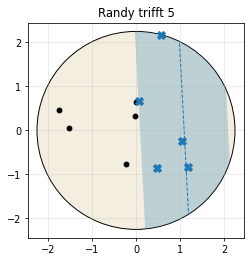

In [ ]:
def anna_automatisch():
    wurf = kluger_wurf(spiel['kegel'], spiel['R'])
    rest = entferne(spiel['kegel'], treffer(spiel['kegel'], wurf))
    beenden = len(rest) > 0 and kluges_beenden(rest, spiel['R'])
    print('Anna wirft (%.2f, %.2f, %d°)%s' % (wurf[0], wurf[1], wurf[2], ', dann beendet sie die Runde' if beenden else ''))
    wirf(wurf[0], wurf[1], wurf[2], beenden)


neues_spiel(N=10, R=2.25, seed=8)

Anna wirft (0.00, -0.06, 0°)
Runde 1: Anna 5, Randy 5, noch 0 Kegel  |  insgesamt: Anna 5, Randy 5
Runde 1 ist zu Ende.
Runde 2: Anna 0, Randy 5, noch 5 Kegel  |  insgesamt: Anna 5, Randy 10


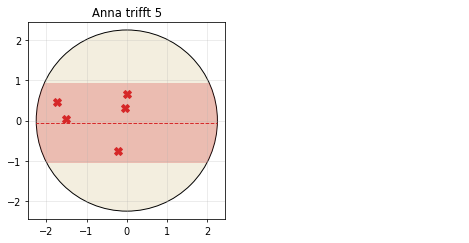

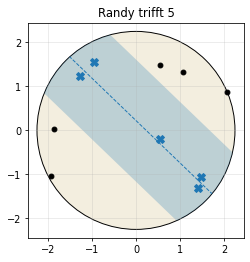

In [ ]:
anna_automatisch()

Anna wirft (-0.07, 0.35, 12°)
Runde 2: Anna 5, Randy 5, noch 0 Kegel  |  insgesamt: Anna 10, Randy 10
Runde 2 ist zu Ende.
Runde 3: Anna 0, Randy 5, noch 5 Kegel  |  insgesamt: Anna 10, Randy 15


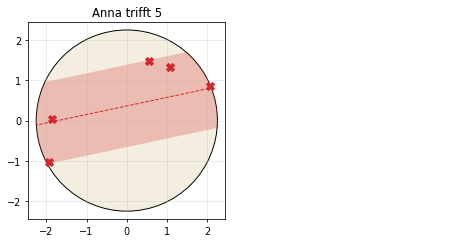

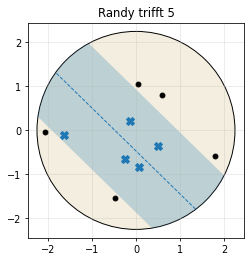

In [ ]:
anna_automatisch()

Über viele Runden sieht man es am besten am Spielstand. Das Bild zeigt für je fünf Spiele den Vorsprung Annas (Annas Punkte minus
Randys Punkte) nach jeder Runde, links bei R = 2,25 und 10 Kegeln, rechts bei der Aufgabe mit R = 2 und 20 Kegeln. Hier zählen wir ganz normal, ohne den
Trick aus Schritt 9, so wie Anna es am Bildschirm sehen würde.

N = 10, R = 2.25: Vorsprung nach 400 Runden: [332, 335, 522, 528, 401]
N = 20, R = 2: Vorsprung nach 400 Runden: [19, 65, -60, 0, -104]


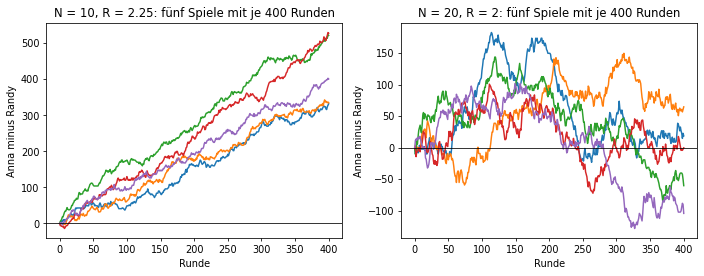

In [ ]:
ANNA = 'klug'
fig, achsen = plt.subplots(1, 2, figsize=(12, 4))
for achse, (N, R) in zip(achsen, [(10, 2.25), (20, 2)]):
    ende = []
    for lauf in range(5):
        stand = [0]
        for r in range(400):
            anna, randy_erster, randy_spaeter, rest = runde(N, R, random.Random(1000000 * (lauf + 10) + r))
            stand.append(stand[-1] + anna - randy_erster - randy_spaeter)
        achse.plot(stand)
        ende.append(stand[-1])
    achse.axhline(0, color='black', linewidth=0.8)
    achse.set_xlabel('Runde')
    achse.set_ylabel('Anna minus Randy')
    achse.set_title('N = %d, R = %g: fünf Spiele mit je 400 Runden' % (N, R))
    print('N = %d, R = %g: Vorsprung nach 400 Runden:' % (N, R), ende)
plt.show()

Links wächst Annas Vorsprung in allen fünf Spielen gleichmäßig, im Mittel um gut einen Kegel je Runde (Schritt 11: Verhältnis knapp
1,2). So sieht es aus, wenn Anna Randy in die Knie zwingt. Rechts entscheidet das Glück: Zwei Spiele gewinnt Anna, eins endet
unentschieden, zwei verliert sie, obwohl sie im Mittel etwa 0,2 Kegel je Runde verliert (nach 400 Runden also etwa 80). Genau deshalb
braucht man für die Frage „Gewinnt Anna bei N = 20?“ die genaue Messung aus Schritt 9.

## Für Neugierige

### Ist der beste Wurf mit ganzen Winkeln wirklich der beste?

Die Lösungshinweise suchen den besten Wurf exakt („MaxPins“): Eine beste Bahn kann man immer so verschieben und drehen, dass zwei
Kegel genau auf ihrem Rand liegen. Für ein Kegelpaar mit Abstand `d` gibt es dafür nur wenige Winkel: Die Lagen der beiden Kegel auf
der Normalen unterscheiden sich um `d · cos(w − β)`, wobei `β` von der Richtung der Verbindungsstrecke abhängt. Dieser Unterschied
soll 0 sein (beide Kegel auf demselben Rand) oder 2 (auf verschiedenen Rändern, nur für `d ≥ 2`). Das ergibt für jedes Paar ein
bis drei **kritische Winkel**. Probiert man nur diese (mit dem Fenster von oben), findet man sicher den besten Wurf, aber man braucht
für N Kegel bis zu `3 · N · (N − 1) / 2` Winkel statt 180.

Weil Kegel genau auf dem Rand liegen, vergleichen wir hier mit einer kleinen Toleranz (`2 + 1e-9`), sonst entscheiden Rundungsfehler.

In [ ]:
def kritische_winkel(kegel):
    winkel = [0.0]
    for a in range(len(kegel)):
        for b in range(a + 1, len(kegel)):
            dx = kegel[b][0] - kegel[a][0]
            dy = kegel[b][1] - kegel[a][1]
            d = math.hypot(dx, dy)
            beta = math.degrees(math.atan2(-dx, dy))       # Lageunterschied = d * cos(w - beta)
            winkel.append((beta + 90) % 180)                # Unterschied 0
            if d >= 2:
                g = math.degrees(math.acos(2 / d))          # Unterschied 2
                winkel.append((beta + g) % 180)
                winkel.append((beta - g) % 180)
    return winkel


def meiste_treffer(kegel, winkelliste):
    beste_zahl = 0
    for winkel in winkelliste:
        w = math.radians(winkel)
        lage = sorted(kx * -math.sin(w) + ky * math.cos(w) for kx, ky in kegel)
        j = 0
        for i in range(len(lage)):
            while lage[i] - lage[j] > 2 + 1e-9:
                j += 1
            beste_zahl = max(beste_zahl, i - j + 1)
    return beste_zahl


for N, R, anzahl in [(10, 2, 1000), (20, 2, 300), (10, 3, 1000), (50, 3, 50)]:
    besser = 0
    for r in range(anzahl):
        kegel = aufstellen(N, R, random.Random(r))
        ganz = meiste_treffer(kegel, range(180))
        exakt = meiste_treffer(kegel, kritische_winkel(kegel))
        if exakt > ganz:
            besser += 1
    print('N = %2d, R = %g: exakt besser in %d von %d Aufstellungen' % (N, R, besser, anzahl))

N = 10, R = 2: exakt besser in 7 von 1000 Aufstellungen
N = 20, R = 2: exakt besser in 4 von 300 Aufstellungen
N = 10, R = 3: exakt besser in 11 von 1000 Aufstellungen
N = 50, R = 3: exakt besser in 3 von 50 Aufstellungen


Nur in etwa 1 % der Aufstellungen verfehlen die ganzen Winkel den besten Wurf (bei 50 Kegeln in 3 von 50). Für die Tabelle in
Schritt 11 spielt das kaum eine Rolle.

### Warum sind die Werte der Hinweise für MaxPins höher?

Im abgedruckten Python-Code der Lösungshinweise steht bei der Richtung der Verbindungsstrecke ein Tippfehler:
`(pins[a].y-pins[b].y)/(pins[a].x-pins[b].y)`, im Nenner müsste `pins[b].x` stehen. Mit dem falschen Winkel liegen die beiden Kegel
nicht mehr auf dem Rand der Bahn. Der Code fügt sie aber trotzdem immer zur Trefferliste hinzu („Randpunkte wegen Rechenungenauigkeit
prüfen“). Dann „trifft“ Anna manchmal Kegel, die gar nicht in ihrer Bahn liegen, und räumt öfter alles ab. Wir zählen, wie oft der
Code mit Tippfehler mehr Treffer meldet, als überhaupt möglich sind.

In [ ]:
def maxpins_hinweise(kegel, tippfehler):
    """Nachbau der Funktion findBest (MaxPins) aus den Lösungshinweisen; gibt die Zahl der gemeldeten Treffer zurück."""
    beste = 1
    for a in range(len(kegel) - 1):
        for b in range(a + 1, len(kegel)):
            (xa, ya), (xb, yb) = kegel[a], kegel[b]
            d = math.hypot(xa - xb, ya - yb)
            px, py = (xa + xb) / 2, (ya + yb) / 2
            alpha = 0
            if xa == xb:
                alpha = math.pi / 2
            elif tippfehler:
                alpha = math.atan((ya - yb) / (xa - yb))
            else:
                alpha = math.atan((ya - yb) / (xa - xb))
            phi = [alpha, alpha]
            if d >= 2:
                phi = phi + [alpha + math.asin(2 / d), alpha - math.asin(2 / d)]
            xs = [px - math.sin(alpha), px + math.sin(alpha), px, px]
            ys = [py + math.cos(alpha), py - math.cos(alpha), py, py]
            for i in range(len(phi)):
                liste = treffer(kegel, (xs[i], ys[i], math.degrees(phi[i])))
                gemeldet = len(liste) + (a not in liste) + (b not in liste)    # a und b werden immer dazugezählt
                beste = max(beste, gemeldet)
    return beste


for N, R in [(5, 3), (10, 2), (10, 3)]:
    zu_viel = 0
    for r in range(300):
        kegel = aufstellen(N, R, random.Random(r))
        if maxpins_hinweise(kegel, True) > meiste_treffer(kegel, kritische_winkel(kegel)):
            zu_viel += 1
        assert maxpins_hinweise(kegel, False) <= meiste_treffer(kegel, kritische_winkel(kegel))
    print('N = %2d, R = %g: mit Tippfehler zu viele Treffer in %d von 300 Aufstellungen' % (N, R, zu_viel))

N =  5, R = 3: mit Tippfehler zu viele Treffer in 91 von 300 Aufstellungen
N = 10, R = 2: mit Tippfehler zu viele Treffer in 89 von 300 Aufstellungen
N = 10, R = 3: mit Tippfehler zu viele Treffer in 127 von 300 Aufstellungen


Mit Tippfehler meldet der Code in etwa einem Drittel der Aufstellungen mehr Treffer, als möglich sind; ohne Tippfehler nie (das
prüft das `assert`). Beim Erstellen dieses Notebooks haben wir ganze Spiele mit diesem Nachbau simuliert (zu langsam für hier): Mit
Tippfehler kamen wir bei R = 3 auf 1,853 (N = 5) und 1,727 (N = 10), fast genau die Werte der Hinweise (1,854 und 1,730), ohne
Tippfehler bei N = 10 auf 1,674, ähnlich wie mit unserer Strategie. Bei R = 2 und N = 20 passt es weniger gut (mit Tippfehler 0,994,
Hinweise 0,987, wir 0,978). Ob der Tippfehler auch im Programm stand, mit dem die Tabelle berechnet wurde, wissen wir also nicht
sicher.

### Weitere Ideen

- **Mehr vorausdenken:** Die kluge Strategie schaut nur auf Randys nächsten Wurf. Man könnte für jeden Kandidaten viele mögliche
  Antworten von Randy auswürfeln und danach Annas besten Wurf suchen. Die Lösungshinweise haben solche Varianten („Smarty“) getestet,
  ohne nennenswerten Gewinn.
- **Andere Felder und Dimensionen:** Mit einer anderen Funktion zum Aufstellen (z. B. Quadrat) oder in drei Dimensionen (Kegel in
  einer Kugel, Bahn als Zylinder) funktioniert alles genauso; nur `anteil_unter` muss man neu herleiten.
- **Gegen kluge Gegner:** Auf dem Turnierserver spielt man gegen Programme, die auch den besten Wurf suchen. Dann wird es wichtig,
  dem Gegner keine guten Würfe übrig zu lassen.

## Zum Schluss: Der beste Wurf mit MiniZinc

Das ganze Spiel mit Zufall und vielen Runden ist nichts für MiniZinc. Aber ein Teil ist eine echte Optimierungsaufgabe: der beste Wurf
für eine feste Aufstellung (Schritt 8). Wir übersetzen ihn so, wie wir ihn auch in Python gesucht haben:

- `winkel` ist eine Variable von 0 bis 179, `mitte` die Lage der Bahn quer zu ihrer Richtung, in Millimetern (MiniZinc rechnet am
  liebsten mit ganzen Zahlen; ein Feld mit Radius 2 hat dann den Radius 2000).
- Die Tabelle `lage[w, i]` enthält für jeden Winkel und jeden Kegel seine Lage quer zur Bahn. Sie kommt aus Python. Im Modell steht
  `lage[winkel, i]`: Die **Variable** `winkel` wird als **Index** verwendet, MiniZinc wählt also gleichzeitig die Zeile der Tabelle.
- `getroffen[i]` ist wahr genau dann, wenn der Kegel höchstens 1000 mm von der Bahnmitte entfernt ist (`<->` heißt „genau dann, wenn“).
- Maximiert wird die Zahl der Treffer.

Neu gegenüber den Arbeitsblättern sind `<->` und `abs`; `sum` über `var bool` zählt die wahren Einträge. Außerdem steht nach
`solve` eine **Suchanweisung**: `int_search([winkel, mitte], input_order, indomain_split)` sagt dem Solver, dass er zuerst den Winkel
und dann die Mitte festlegen soll (`input_order`: in dieser Reihenfolge) und dabei den Wertebereich immer wieder halbiert
(`indomain_split`). Ohne diese Zeile hat Gecode bei `kegel4.txt` nach 60 Sekunden erst einen Wurf mit 11 Treffern gefunden.
```minizinc
int: n;                                           % Anzahl der Kegel
int: R;                                           % Radius des Spielfelds in mm
array[0..179, 1..n] of int: lage;                 % Lage von Kegel i quer zur Bahn bei Winkel w, in mm

var 0..179: winkel;
var -R..R: mitte;                                 % Lage der Bahnmitte quer zur Bahn
array[1..n] of var bool: getroffen;

constraint forall(i in 1..n)(getroffen[i] <-> abs(lage[winkel, i] - mitte) <= 1000);

var int: anzahl = sum(i in 1..n)(getroffen[i]);
solve :: int_search([winkel, mitte], input_order, indomain_split) maximize anzahl;

output ["Winkel \(winkel)°, Mitte \(mitte) mm: \(anzahl) Kegel getroffen\n",
        "Kegel:", concat([" \(i)" | i in 1..n where fix(getroffen[i])]), "\n"];
```

Die Datendatei schreibt `als_dzn`. Wir runden auf ganze Millimeter; das kann in sehr seltenen Fällen einen Kegel genau auf den Rand
schieben, deshalb vergleichen wir das Ergebnis mit Python.

In [ ]:
def als_dzn(kegel, R):
    zeilen = []
    for winkel in range(180):
        w = math.radians(winkel)
        nx, ny = -math.sin(w), math.cos(w)
        werte = []
        for kx, ky in kegel:
            werte.append(str(round(1000 * (kx * nx + ky * ny))))
        zeilen.append(', '.join(werte))
    return ('n = %d;\nR = %d;\nlage = array2d(0..179, 1..n, [\n%s]);' %
            (len(kegel), round(1000 * R), ',\n'.join(zeilen)))


kegel2, R2 = lies_kegel('beispieldaten/kegel2.txt')
print(als_dzn(kegel2, R2)[:160], '...')

n = 10;
R = 2000;
lage = array2d(0..179, 1..n, [
-630, 242, -1821, 1529, -968, 1279, 814, -55, -534, 1325,
-662, 235, -1818, 1539, -947, 1264, 832, -85, -501, 1 ...


**Ausgabe von Gecode für `kegel1.txt`** (die Zeile `==========` heißt: optimal bewiesen; vorher stehen die besseren Zwischenlösungen,
die der Solver unterwegs gefunden hat):

**Ausgabe:**

```
Winkel 0°, Mitte 316 mm: 16 Kegel getroffen
Kegel: 1 3 5 6 7 9 10 11 12 13 14 15 16 17 18 19
----------
==========
```

| Datei | Treffer MiniZinc | Treffer `bester_wurf` |
|---|---|---|
| `kegel1.txt` | 16 | 16 |
| `kegel2.txt` | 7 | 7 |
| `kegel3.txt` | 7 | 7 |
| `kegel4.txt` | 28 | 28 |

MiniZinc und unser gleitendes Fenster finden bei allen vier Aufstellungen gleich viele Treffer (die Kegelnummern zählen in MiniZinc ab 1).
Der Wurf selbst kann ein anderer sein, oft gibt es mehrere beste.

**Laufzeit.** Beim Erstellen dieses Notebooks haben wir alle vier Aufstellungen mit vier Solvern gerechnet:
- **Gecode** mit Suchanweisung: jede Aufstellung in etwa 0,2 Sekunden. Ohne Suchanweisung 0,2 bis 4 Sekunden für die ersten drei, bei
  `kegel4.txt` (50 Kegel) nach 60 Sekunden noch kein bester Wurf.
- **Chuffed** mit Suchanweisung bis 0,5 Sekunden, bei `kegel4.txt` gut 4 Sekunden (ohne 20 Sekunden).
- **CP-SAT** 2 bis 16 Sekunden; ohne Suchanweisung bei `kegel4.txt` gar nicht fertig, der Prozess musste beendet werden.
- **HiGHS** (ein Löser für lineare Modelle, er beachtet die Suchanweisung nicht) 3 bis 22 Sekunden; bei `kegel4.txt` hat er den besten
  Wurf zwar gefunden, aber nach 60 Sekunden noch nicht bewiesen, dass es keinen besseren gibt.

Die Suchanweisung passt genau zu unserem Python-Verfahren: Ist der Winkel erst einmal fest, ist der Rest ein einfaches eindimensionales
Problem, das der Solver durch Halbieren der Mitte schnell löst.

Für das Spiel ist MiniZinc trotzdem keine gute Wahl: Anna braucht in einer Simulation Tausende beste Würfe, und das gleitende Fenster
ist dafür viel schneller und genauso genau. MiniZinc ist hier eine unabhängige Probe, dass das Fenster wirklich den besten Wurf findet.